# 6. Invertibility, Isomorphism and Change of Basis
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The shifts on sequences. A sequence $x$ (top), its forward shift $Fx$, then $BFx=x$: nothing is lost. But $FBx$ (bottom) has lost $x_1$: the backward shift forgot it and the forward shift cannot recover it. In infinite dimensions a one-sided inverse need not be two-sided.

Text(0.5, 0, 'index $k$ (the sequence continues forever)')

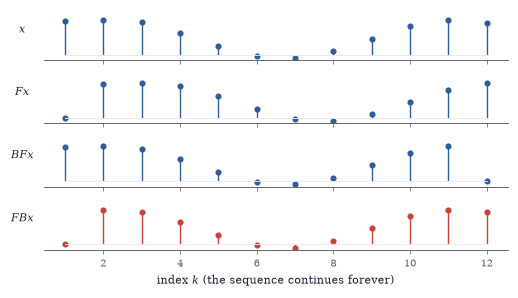

In [2]:
k = np.arange(1, 13)
x = np.sin(0.7 * k) + 0.3 * (k == 1) + 0.8
F = lambda s: np.r_[0, s[:-1]]
B = lambda s: np.r_[s[1:], 0]
rows = [("$x$", x), ("$Fx$", F(x)), ("$BFx$", B(F(x))), ("$FBx$", F(B(x)))]
fig, axs = plt.subplots(4, 1, figsize=(W, 2.6), sharex=True)
for ax, (lab, s) in zip(axs, rows):
    stem_spectrum(ax, s, color=RED if lab == "$FBx$" else BLUE)
    ax.set_ylabel(lab, rotation=0, labelpad=14, fontsize=7.5); ax.set_yticks([]); ax.set_ylim(-0.3, 2.3)
    ax.spines["left"].set_visible(False)
axs[-1].set_xlabel("index $k$ (the sequence continues forever)")

Invertible and non-invertible operators on $\R^2$. Left, an invertible $A$ sends the grid to a grid of parallelograms and the unit circle to an ellipse, and $A^{-1}$ (dashed, applied to the image) restores both exactly. Middle, a nearly singular $A$ squashes the circle into a thin ellipse; it is still invertible, but its inverse must stretch enormously. Right, a singular $A$ collapses the plane onto a line, and no linear map can undo the collapse.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


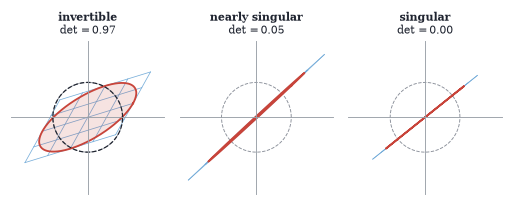

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

mats = [("invertible", np.array([[1.3, 0.5], [0.4, 0.9]])),
        ("nearly singular", np.array([[1.0, 0.95], [0.9, 0.9]])),
        ("singular", np.array([[1.0, 0.5], [0.8, 0.4]]))]
fig, axs = plt.subplots(1, 3, figsize=(W, 1.75))
for ax, (name, A) in zip(axs, mats):
    plane(ax, 2.2, grid=False)
    grid_image(ax, A, lim=1, n=5, color=SKY, lw=0.5, base=False)
    unit_circle(ax, color=GRAY, lw=0.6)
    circle_image(ax, A, color=RED, lw=1.2, fill=0.15)
    if name == "invertible":
        P = circle_image(ax, np.linalg.inv(A) @ A, color=INK, lw=0.8, fill=0, ls="--")
    ax.set_title(f"{name}\n" + rf"$\det={np.linalg.det(A):.2f}$", fontsize=7)

A polynomial is a vector once a basis is chosen. The cubic $p$ (left) has coordinate vectors $(1.0,-0.5,-1.2,0.9)$ in the monomial basis $1,x,x^2,x^3$ and a different list in the Bernstein basis on $[0,1]$ (right); in the Bernstein basis the coordinates are control points that the curve follows (dots, plotted at $k/3$).

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


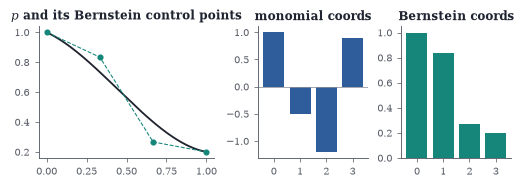

In [4]:
from math import comb
x = np.linspace(0, 1, 200)
c_mono = np.array([1.0, -0.5, -1.2, 0.9])
p = np.polynomial.Polynomial(c_mono)
Bmat = np.array([[comb(3, k) * t ** k * (1 - t) ** (3 - k) for k in range(4)] for t in np.linspace(0, 1, 4)])
V = np.vander(np.linspace(0, 1, 4), 4, increasing=True)
c_bern = np.linalg.solve(Bmat, V @ c_mono)            # match values at 4 nodes
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
axs[0].plot(x, p(x), color=INK); axs[0].plot(np.arange(4) / 3, c_bern, "o--", color=TEAL, ms=3, lw=0.7)
axs[0].set_title("$p$ and its Bernstein control points")
axs[1].bar(range(4), c_mono, color=BLUE); axs[1].set_title("monomial coords"); axs[1].set_xticks(range(4))
axs[2].bar(range(4), c_bern, color=TEAL); axs[2].set_title("Bernstein coords"); axs[2].set_xticks(range(4))
for ax in axs[1:]: ax.axhline(0, color=GRAY, lw=0.5)

One operator, two bases. Left, $T$ in the standard basis, with matrix $M=\begin{bmatrix}2&1\\0&1\end{bmatrix}$, shown acting on a grid: the action looks like a shear combined with a stretch. Right, the same $T$ described in the basis $u_1=(1,0)$, $u_2=(-1,1)$, drawn as the grid of $u$-coordinates; in this basis the matrix is $A^{-1}MA=\operatorname{diag}(2,1)$, and $T$ simply doubles the $u_1$-coordinate.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


A^{-1} M A =
 [[2. 0.]
 [0. 1.]]


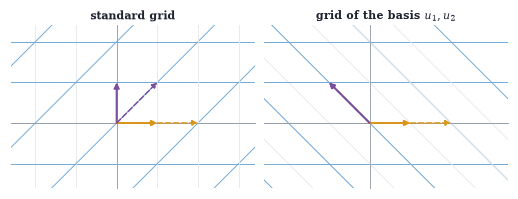

In [5]:
M = np.array([[2.0, 1.0], [0.0, 1.0]])
Abas = np.array([[1.0, -1.0], [0.0, 1.0]])                 # columns u1, u2
print("A^{-1} M A =\n", np.linalg.inv(Abas) @ M @ Abas)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.3))
for ax, B, title in [(axs[0], np.eye(2), "standard grid"), (axs[1], Abas, "grid of the basis $u_1,u_2$")]:
    plane(ax, (-2.6, 3.4, -1.6, 2.4), grid=False)
    t = np.linspace(-3, 3, 2)
    for c in np.arange(-3, 4):
        for P in (B @ np.vstack([t, c + 0 * t]), B @ np.vstack([c + 0 * t, t])):
            ax.plot(*P, color=LIGHT, lw=0.6)
            ax.plot(*(M @ P), color=SKY, lw=0.6)
    arrow(ax, B[:, 0], color=GOLD, lw=1.3); arrow(ax, B[:, 1], color=PLUM, lw=1.3)
    arrow(ax, M @ B[:, 0], color=GOLD, lw=1.0, ls="--"); arrow(ax, M @ B[:, 1], color=PLUM, lw=1.0, ls="--")
    ax.set_title(title, fontsize=7.5)

In [6]:
# Similar matrices share rank, trace, determinant and eigenvalues; entries need not agree.
rng = np.random.default_rng(0)
M = rng.integers(-3, 4, size=(4, 4)).astype(float)
A = rng.normal(size=(4, 4))
B = np.linalg.inv(A) @ M @ A
for name, f in [("rank", np.linalg.matrix_rank), ("trace", np.trace), ("det", np.linalg.det)]:
    print(f"{name:6s} M: {f(M): .6f}   B: {f(B): .6f}")
print("eigenvalues of M:", np.sort_complex(np.linalg.eigvals(M)).round(6))
print("eigenvalues of B:", np.sort_complex(np.linalg.eigvals(B)).round(6))
print("largest entry difference |M - B|:", np.abs(M - B).max().round(3))

rank   M:  4.000000   B:  4.000000
trace  M:  2.000000   B:  2.000000
det    M: -29.000000   B: -29.000000
eigenvalues of M: [-1.626231+0.j       -0.447548-1.934895j -0.447548+1.934895j
  4.521328+0.j      ]
eigenvalues of B: [-1.626231+0.j       -0.447548-1.934895j -0.447548+1.934895j
  4.521328+0.j      ]
largest entry difference |M - B|: 8.82


Solving $Ax=b$ when $b$ is known only approximately. For each matrix, $500$ right-hand sides scattered in a small disc around $b$ (left of each pair, in the space of $b$) produce solutions $x=A^{-1}b$ (right). For a well-conditioned $A$ the cloud of solutions stays compact; for an ill-conditioned one it is stretched into a long streak along the direction that $A$ nearly collapses.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


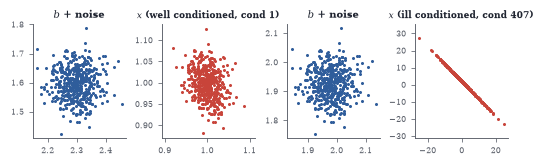

In [7]:
rng = np.random.default_rng(1)
pts = rng.normal(size=(2, 500)) * 0.05
mats = [("well conditioned", np.array([[2.0, 0.3], [0.1, 1.5]])), ("ill conditioned", np.array([[1.0, 0.98], [0.97, 0.96]]))]
fig, axs = plt.subplots(1, 4, figsize=(W, 1.4))
for k, (name, A) in enumerate(mats):
    b = A @ np.array([1.0, 1.0])
    X = np.linalg.solve(A, b[:, None] + pts)
    axs[2 * k].scatter(*(b[:, None] + pts), s=1, color=BLUE); axs[2 * k].set_title(f"$b$ + noise", fontsize=6.5)
    axs[2 * k + 1].scatter(*X, s=1, color=RED); axs[2 * k + 1].set_title(f"$x$ ({name}, cond {np.linalg.cond(A):.0f})", fontsize=6)
    for ax in axs[2 * k:2 * k + 2]:
        ax.set_aspect("equal", adjustable="datalim"); ax.tick_params(labelsize=5)

In [8]:
rng = np.random.default_rng(3)
A, B, D = rng.normal(size=(2, 2)), rng.normal(size=(2, 3)), rng.normal(size=(3, 3))
Mbig = np.block([[A, B], [np.zeros((3, 2)), D]])
Ai, Di = np.linalg.inv(A), np.linalg.inv(D)
formula = np.block([[Ai, -Ai @ B @ Di], [np.zeros((3, 2)), Di]])
print("formula matches numpy inverse:", np.allclose(formula, np.linalg.inv(Mbig)))

formula matches numpy inverse: True


In [9]:
N = np.array([[0, 1, 0], [0, 0, 2], [0, 0, 0.0]])
A = np.array([[1, -1, 1], [0, 1, -2], [0, 0, 1.0]])
print(np.linalg.inv(A) @ N @ A)

[[0. 1. 0.]
 [0. 0. 2.]
 [0. 0. 0.]]
